In [80]:
import pandas as pd
import numpy as np
import random

from helper import *
from plots import *
from nlp import *

In [39]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [40]:
df = pd.read_csv('data/data_preprocessed.csv')

In [41]:
# Фиксация состояния генератора псевдослучайных чисел для воспроизводимости результатов
SEED = 42
np.random.seed(SEED)
random.seed(SEED) 


### 1. Изучение структуры данных

In [42]:
df.info()
# - количетсв записей (50000)
# - количество столбцов (4)
# - типы данных в каждом столбце
# - количество пропущенных значений отсутствуют.

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   text          50000 non-null  str  
 1   label         50000 non-null  int64
 2   cleaned_text  50000 non-null  str  
 3   token_count   50000 non-null  int64
dtypes: int64(2), str(2)
memory usage: 1.5 MB


### 2. Проверка на корректность и качество данных

#### 2.1 Проверка на дубликаты

In [43]:
df.duplicated().sum()

np.int64(418)

In [45]:
# дупликаты нужно удалить.
df.drop_duplicates(inplace=True)
print("Осталось дубликатов:", df.duplicated().sum())

Осталось дубликатов: 0


#### 2.2 Пропущенные значения

In [47]:
df.isnull().sum() #пропусков нет. Отлично.

text            0
label           0
cleaned_text    0
token_count     0
dtype: int64

In [50]:
short_texts = df[df['token_count'] < 10]
print(f"Количество отзывов короче 10 слов: {len(short_texts)}")

Количество отзывов короче 10 слов: 5


In [51]:
print(short_texts['text'].head(10))

13109    More suspenseful, more subtle, much, much more...
27521                     Read the book, forget the movie!
28920    Primary plot!Primary direction!Poor interpreta...
31072            What a script, what a story, what a mess!
40817    I hope this group of film-makers never re-unites.
Name: text, dtype: str


In [53]:
# Перезаписываем df, оставляя только строки, где слов 10 или больше (выполнение условий задания)
df = df[df['token_count'] >= 10]

In [62]:
unknown_count = df['text'].str.contains('unknown', case=False, na=False).sum()
print(f"Количество отзывов, содержащих слово 'unknown': {unknown_count}") # эти строки мы не удаляем, для нас это ценная информация, отзывы могут содержать слово 'unknown'

Количество отзывов, содержащих слово 'unknown': 583


### 3. Детальное изучение признаков (и таргета)

In [64]:
df_EDA = df.copy() # копируем для экспериментов

### 3.1. Таргет (целевая переменная)

In [65]:
df_EDA['label'].value_counts()

label
1    24884
0    24693
Name: count, dtype: int64

### 3.2. Анализ отзывов (text)

In [67]:
df_EDA['text_char_lenght'] = df_EDA['text'].str.len()

In [68]:
df_EDA['text_char_lenght'].describe()

count    49577.000000
mean      1310.695685
std        990.730896
min         52.000000
25%        699.000000
50%        971.000000
75%       1592.000000
max      13704.000000
Name: text_char_lenght, dtype: float64

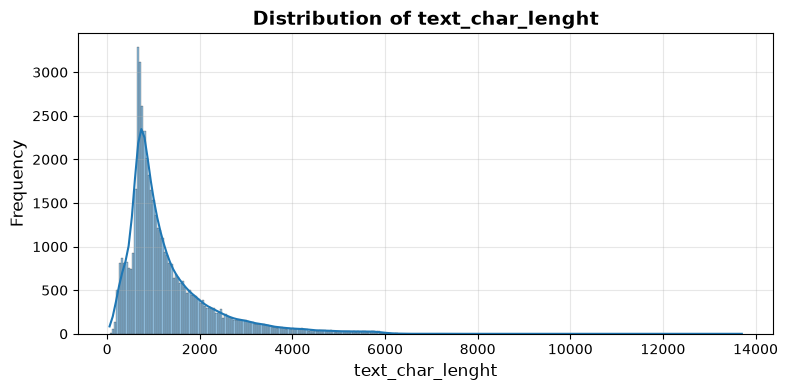

In [72]:
plot_hist_numeric(df_EDA, 'text_char_lenght') # Большинство отзывов находятся на уровне 1000 символов(150-200 слов), но хвост довольно длинный.

In [73]:
df_EDA['text_tokenized_tiktoken'] = df_EDA['text'].apply(tokenize_tiktoken)
df_EDA['text_tokenized_tiktoken_len'] = df_EDA['text_tokenized_tiktoken'].apply(len)

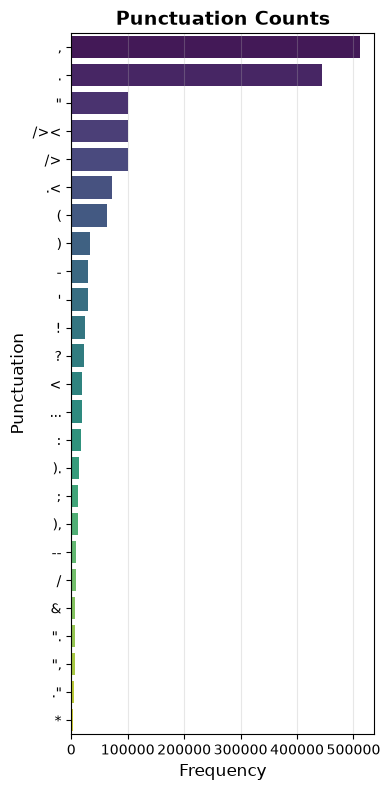

In [81]:
punct_res = punctuation_counts(df_EDA, 'text_tokenized_tiktoken')
barplot(punct_res, title='Punctuation Counts', ylabel='Punctuation', top_n=25, figsize=(4, 8))

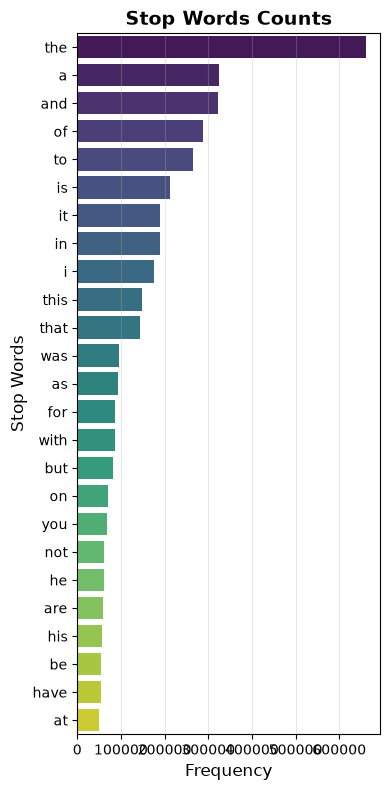

In [82]:
stop_words_counts = stopwords_count(df_EDA, 'text_tokenized_tiktoken')
barplot(stop_words_counts, title='Stop Words Counts', ylabel='Stop Words', top_n=25, figsize=(4, 8))

In [ ]:
# Подсчет частотности токенов в описаниях (без стоп-слов и пунктуации)
token_counts = token_counts(
    df_EDA, 
    'text_tokenized_tiktoken', 
    remove_stopwords=True, 
    remove_punctuation=True,
    lowercase_for_counting=True
)

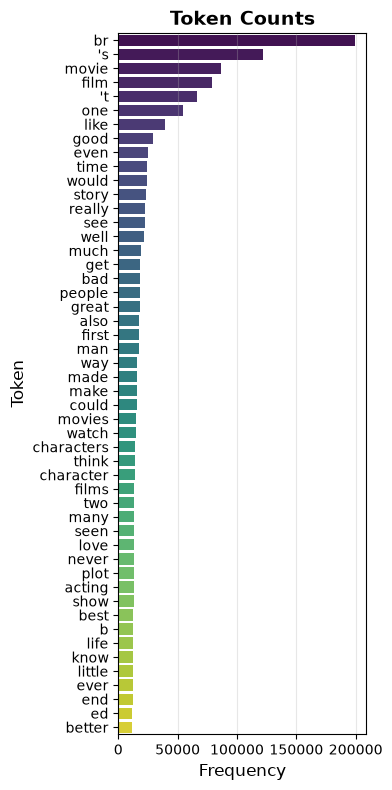

In [ ]:
barplot(token_counts, title='Token Counts', ylabel='Token', top_n=50, figsize=(4, 8))# Топ-50 самых частых токенов в отзывах. Видим, что перенос строки самое популярное(отфильтруем позже).

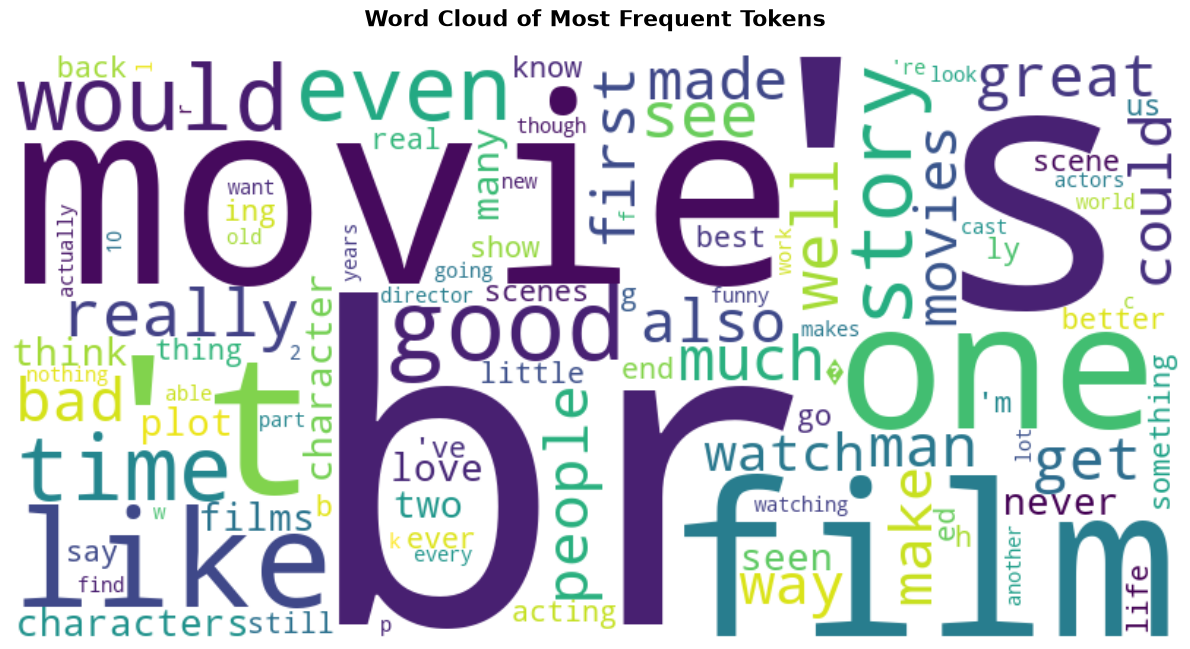

In [87]:
plot_wordcloud(token_counts, title='Word Cloud of Most Frequent Tokens', max_words=100)# Облако слов для отзывов

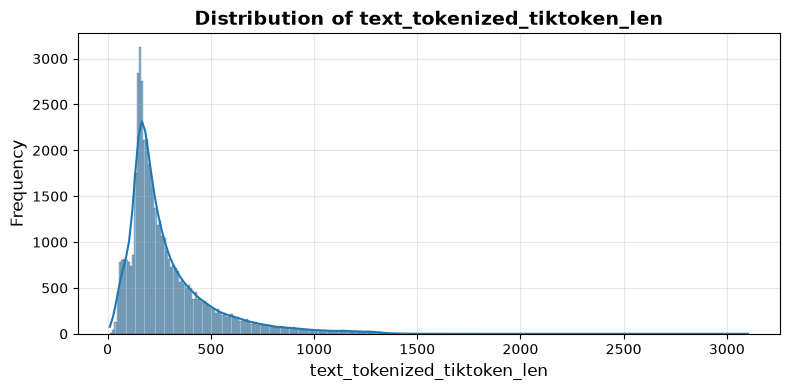

In [89]:
# Распределение количества токенов в отзывах
plot_hist_numeric(df_EDA, 'text_tokenized_tiktoken_len')

In [90]:
df_EDA['text_tokenized_tiktoken_clean'] = df_EDA['text_tokenized_tiktoken'].apply(lambda tokens: filter_tokens(
    tokens,
    remove_stopwords=True,
    remove_punct_tokens=True,
    lowercase_for_counting=True
))

In [93]:
# Анализ важности токенов в отзывах для классификации. Выявляем, какие слова и фразы лучше всего различают позитивный и негативный отзывы.
counts = count_based_analysis(
    texts_tokenized = df_EDA['text_tokenized_tiktoken_clean'], 
    labels = df_EDA['label'], 
    n=3,
    metric='anova_f',
    min_count=50
)

In [94]:
# Настраиваем отображение чисел с плавающей точкой для лучшей читаемости
pd.set_option('display.float_format', lambda x: '%.5f' % x)

In [95]:
# Выводим результаты анализа важности токенов
counts

,token,metric,count_0,freq_0,count_1,freq_1,total_count
0,bad,3566.63448,14630,0.00140,3776,0.00035,18406
1,worst,2811.53126,4604,0.00044,428,0.00004,5032
2,great,2133.71310,5144,0.00049,12890,0.00119,18034
3,waste,1870.00933,2536,0.00024,171,0.00002,2707
4,awful,1602.84759,2844,0.00027,284,0.00003,3128
...,...,...,...,...,...,...,...
24366,int,0.00001,373,0.00004,376,0.00003,749
24367,one -l iners,0.00001,124,0.00001,125,0.00001,249
24368,flash backs,0.00001,251,0.00002,253,0.00002,504
24369,ore,0.00000,395,0.00004,398,0.00004,793


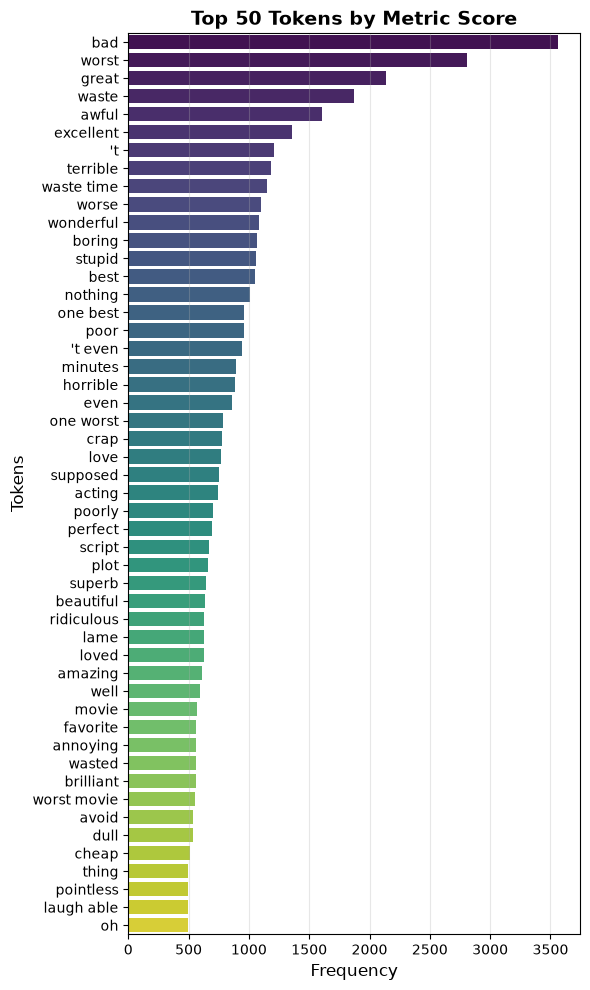

In [96]:
# Визуализация топ-50 наиболее важных для классификации токенов в отзывах
barplot_data_metric = counts.set_index('token')['metric'].head(50)
barplot(barplot_data_metric, 'Top 50 Tokens by Metric Score', 'Tokens', figsize=(6, 10))

### Вывод по этапу фильтрации и статистического анализа:
1. Переход от анализа сырых токенов к фильтрации с помощью функции `filter_tokens` позволил успешно избавиться от выявленного ранее шума (включая технический токен `br`), стоп-слов и знаков препинания.
2. Применение метрики `anova_f` с параметром `n=3` (учет n-грамм до 3 слов) позволяет выявить не просто самые частые слова, а устойчивые смысловые маркеры (словосочетания), которые имеют максимальную разделительную способность между классами `positive` и `negative`.